# Predicción de Propinas del Mesero con Machine Learning

**Fuente:** [GeeksforGeeks — Waiter's Tip Prediction using Machine Learning](https://www.geeksforgeeks.org/machine-learning/waiters-tip-prediction-using-machine-learning/)  
**Ejecución:** Carlos Francisco Montoya Urzua

---

Si recientemente has visitado un restaurante para una cena o comida familiar y le has dado propina al mesero por su amable servicio, este proyecto puede entusiasmarte. En este artículo intentaremos predecir qué cantidad de propina dará una persona según su visita al restaurante, utilizando algunas características relacionadas con la misma.

Empecemos importando algunas librerías que se utilizarán para diversos propósitos, los cuales se explicarán más adelante en este artículo.

## Importación de Librerías y el Dataset

Las librerías de Python nos facilitan enormemente el manejo de datos y la realización de tareas típicas y complejas con una sola línea de código.

- **Pandas** — Esta librería ayuda a cargar el dataframe en formato de arreglo 2D y tiene múltiples funciones para realizar tareas de análisis de una sola vez.
- **Numpy** — Los arreglos de NumPy son muy rápidos y pueden realizar grandes cómputos en muy poco tiempo.
- **Matplotlib / Seaborn** — Esta librería se usa para crear visualizaciones.
- **Sklearn** — Este módulo contiene múltiples librerías con funciones pre-implementadas para realizar tareas desde el preprocesamiento de datos hasta el desarrollo y evaluación de modelos.
- **XGBoost** — Contiene el algoritmo de machine learning eXtreme Gradient Boosting, uno de los algoritmos que nos ayuda a lograr alta precisión en las predicciones.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error as mae
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor

import warnings
warnings.filterwarnings('ignore')

Ahora usemos el dataframe de pandas para cargar el dataset y observar las primeras cinco filas.

> **Nota:** Puedes descargar el dataset desde [aquí](https://media.geeksforgeeks.org/wp-content/uploads/20240905120803/tips.csv) o directamente desde Kaggle.

In [2]:
df = pd.read_csv('tips.csv')
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


**Salida:** Primeras cinco filas del dataset, que contiene columnas como `total_bill`, `tip`, `sex`, `smoker`, `day`, `time` y `size`.

In [3]:
df.shape

(244, 7)

Este dataset contiene muy pocas filas, pero el procedimiento será el mismo sin importar si el dataset tuviera 20,000 filas de datos.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    object 
 3   smoker      244 non-null    object 
 4   day         244 non-null    object 
 5   time        244 non-null    object 
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), object(4)
memory usage: 13.5+ KB


**Salida:** Detalles sobre las columnas del dataset.

De lo anterior, podemos ver que el dataset contiene 2 columnas con valores flotantes, 4 con valores categóricos y el resto contiene valores enteros.

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
total_bill,244.0,19.785943,8.902412,3.07,13.3475,17.795,24.1275,50.81
tip,244.0,2.998279,1.383638,1.00,2.0000,2.900,3.5625,10.00
size,244.0,2.569672,0.951100,1.00,2.0000,2.000,3.0000,6.00


**Salida:** Medidas estadísticas descriptivas de los datos continuos disponibles en el dataset.

Podemos observar las medidas estadísticas descriptivas de los datos continuos disponibles en el dataset.

## Análisis Exploratorio de Datos (EDA)

El **EDA** (*Exploratory Data Analysis*) es un enfoque para analizar los datos mediante técnicas visuales. Se utiliza para descubrir tendencias y patrones, o para verificar supuestos con la ayuda de resúmenes estadísticos y representaciones gráficas. Al realizar el EDA de este dataset, intentaremos ver cuál es la relación entre las características independientes, es decir, cómo una afecta a la otra.

In [6]:
df.isnull().sum()

,0
total_bill,0
tip,0
sex,0
smoker,0
day,0
time,0
size,0


**Salida:** Conteo de valores nulos por columna.

No hay valores nulos en el dataset dado. Por lo tanto, podemos continuar con la parte de análisis de datos.

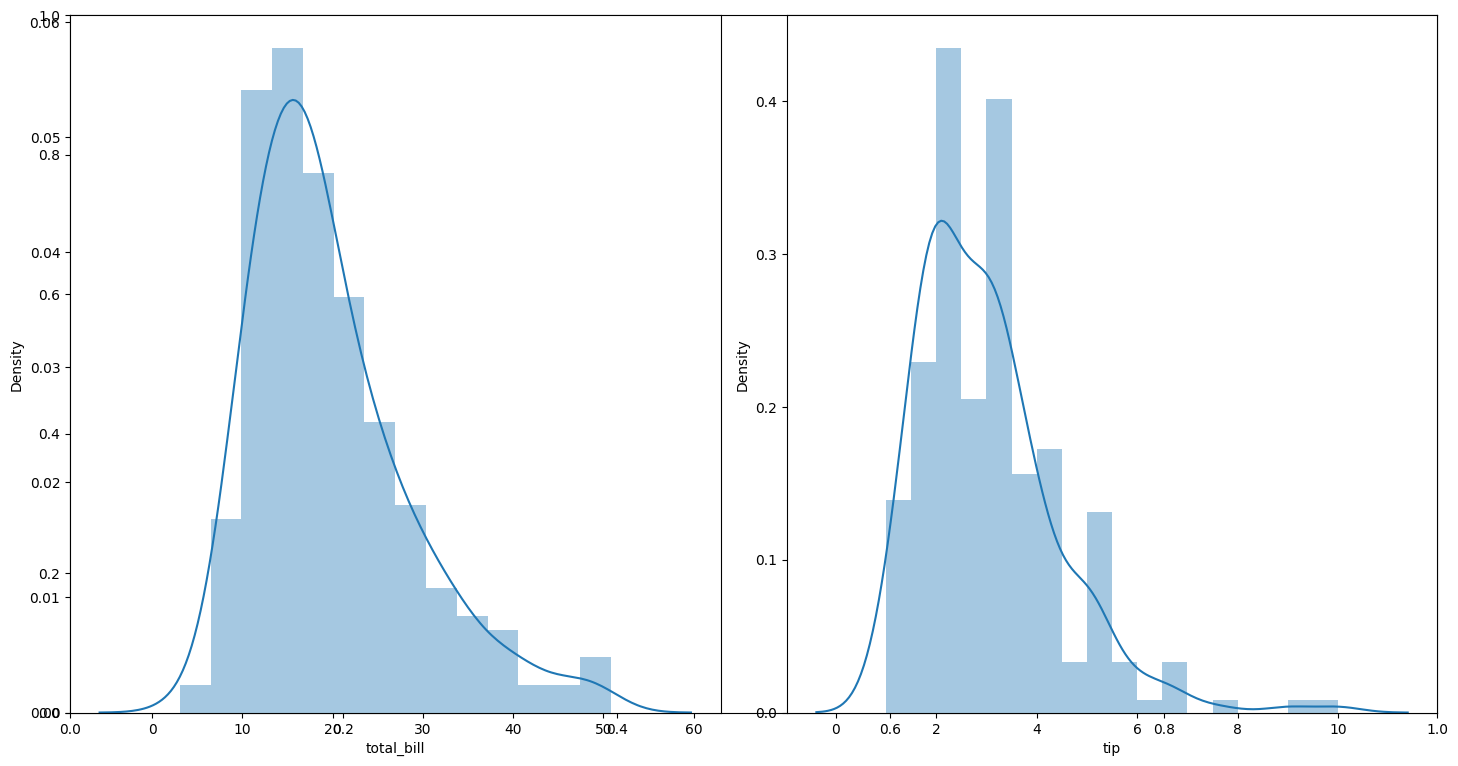

In [7]:
plt.subplots(figsize=(15, 8))

for i, col in enumerate(['total_bill', 'tip']):
    plt.subplot(1, 2, i + 1)
    sb.distplot(df[col])
plt.tight_layout()
plt.show()

**Salida:** Gráficos de distribución de las columnas de datos continuos.

De los gráficos anteriores, podemos concluir que la distribución de datos está ligeramente sesgada hacia la derecha (sesgada positivamente). Esto se observa generalmente porque la mayoría de las personas gastan en un rango determinado, pero algunas realizan gastos tan elevados que la distribución se vuelve **positivamente asimétrica**.

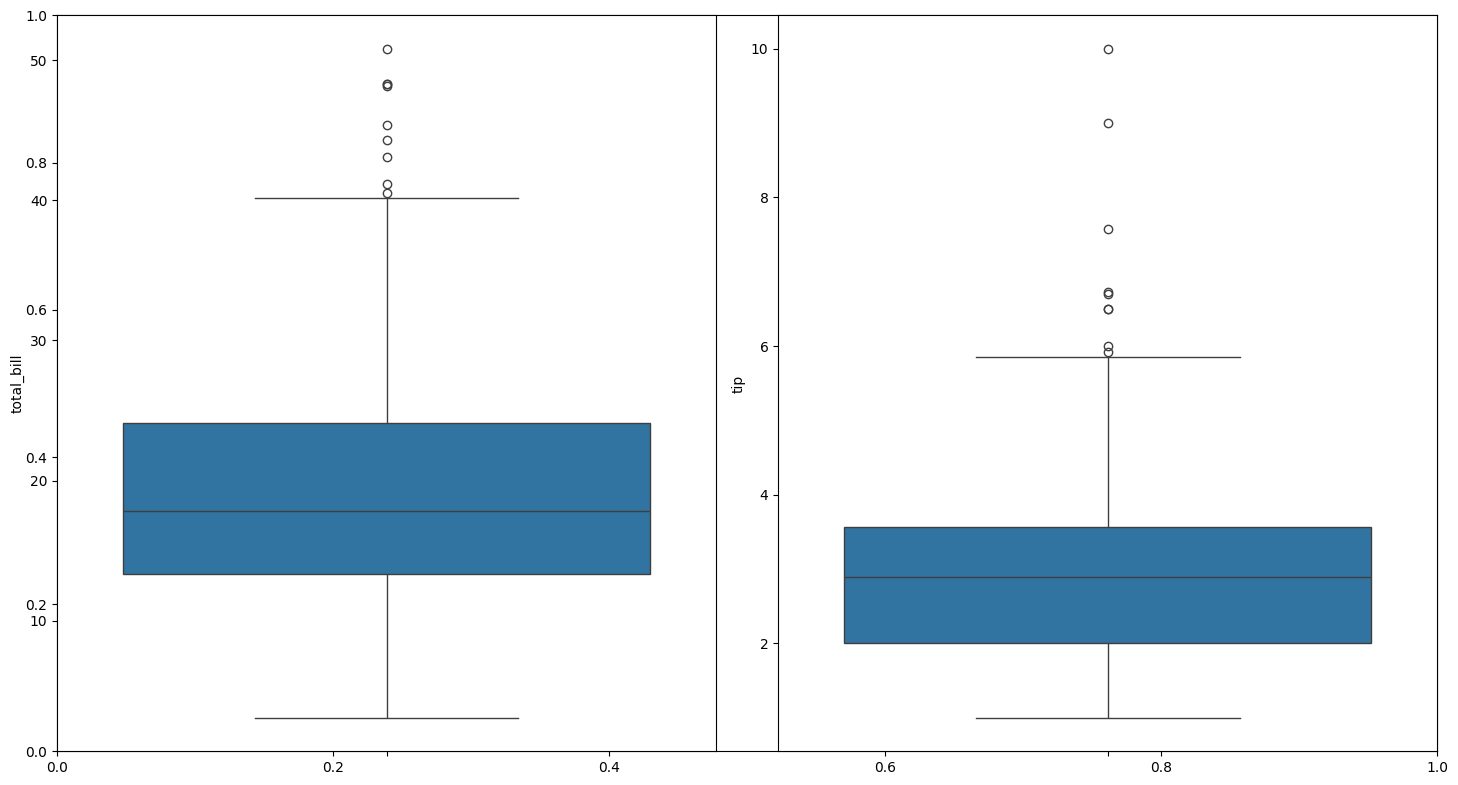

In [8]:
plt.subplots(figsize=(15, 8))

for i, col in enumerate(['total_bill', 'tip']):
    plt.subplot(1, 2, i + 1)
    sb.boxplot(df[col])
plt.tight_layout()
plt.show()

**Salida:** Diagramas de caja (*boxplots*) para identificar los valores atípicos.

De los boxplots anteriores, podemos decir que hay valores atípicos en el dataset. Sin embargo, ya tenemos muy poca cantidad de datos; si eliminamos más filas no sería una buena idea. Pero verifiquemos cuántas filas tendríamos que eliminar para deshacernos de los valores atípicos.

In [9]:
df.shape, df[(df['total_bill'] < 45) & (df['tip'] < 7)].shape

((244, 7), (238, 7))

Solo tendremos que perder 6 puntos de datos para eliminar la mayoría de los valores atípicos, así que hagámoslo.

In [10]:
df = df[(df['total_bill'] < 45) & (df['tip'] < 7)]

Dibujemos el gráfico de conteo para las columnas categóricas.

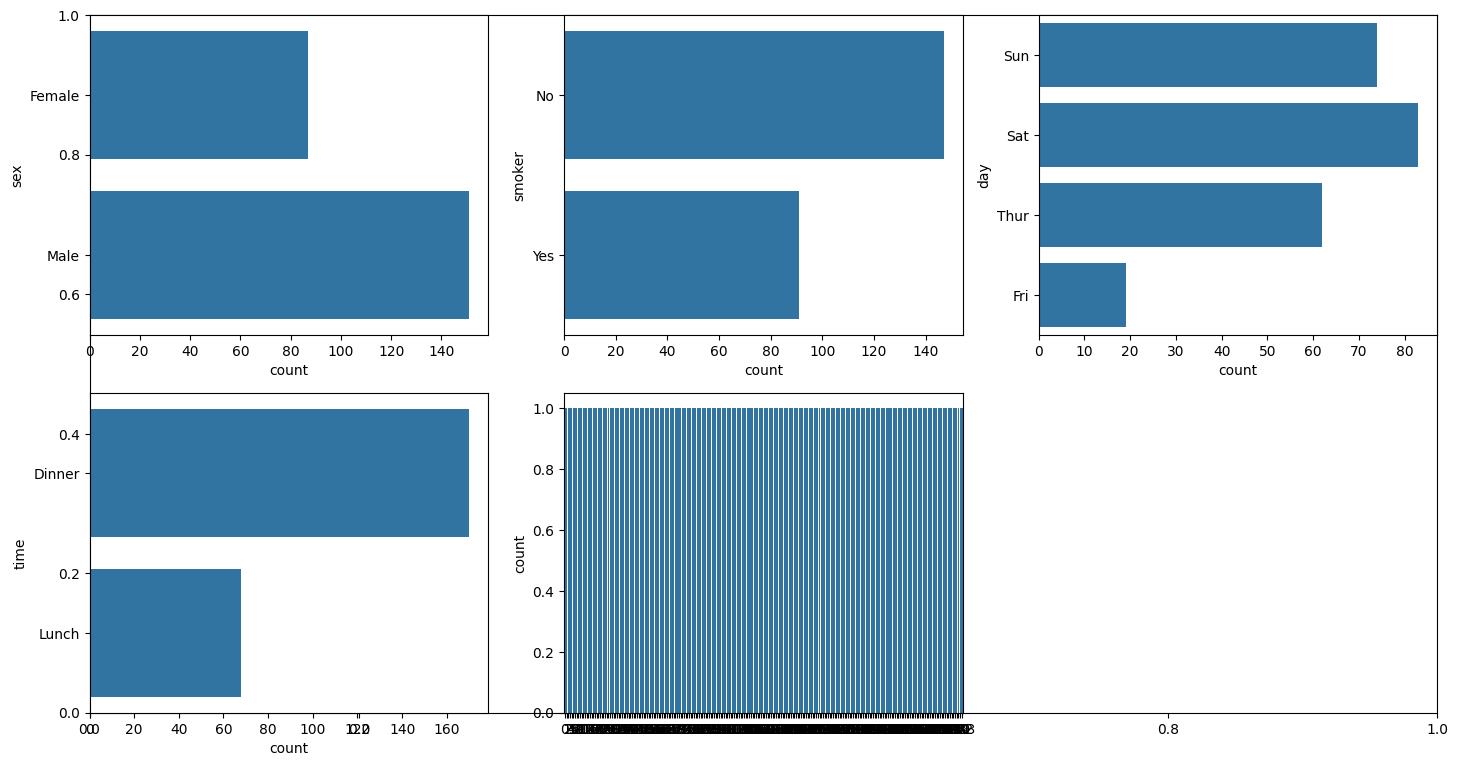

In [11]:
feat = df.loc[:, 'sex':'size'].columns

plt.subplots(figsize=(15, 8))
for i, col in enumerate(feat):
    plt.subplot(2, 3, i + 1)
    sb.countplot(df[col])
plt.tight_layout()
plt.show()

**Salida:** Gráfico de conteo para las columnas categóricas.

Aquí podemos extraer algunas observaciones:

- La afluencia de clientes los fines de semana es mayor que entre semana.
- Las personas generalmente prefieren cenar fuera en comparación con almorzar.
- Ir solo al restaurante es tan poco frecuente como ir con una familia de 5 o 6 personas.

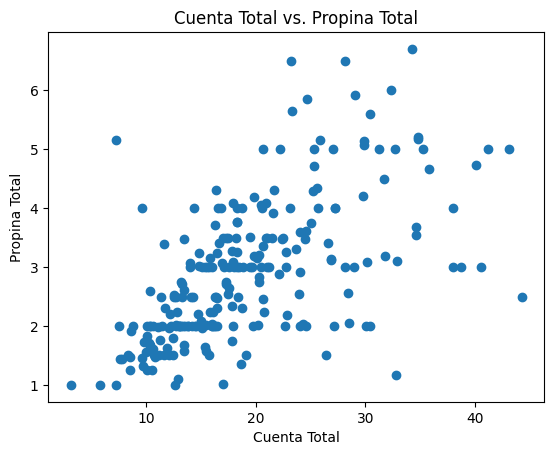

In [12]:
plt.scatter(df['total_bill'], df['tip'])
plt.title('Cuenta Total vs. Propina Total')
plt.xlabel('Cuenta Total')
plt.ylabel('Propina Total')
plt.show()

**Salida:** Gráfico de dispersión (*scatter plot*) entre la cuenta total y la propina.

Veamos cuál es la relación entre el tamaño del grupo familiar y la propina dada.

In [13]:
# Se establece el parámetro numeric_only=True para evitar calcular la media de columnas no numéricas
df.groupby(['size']).mean(numeric_only=True)

# Este código fue modificado por Susobhan Akhuli

,total_bill,tip
size,,
1,7.242500,1.437500
2,16.448013,2.582308
3,21.899722,3.206667
4,27.137647,3.814706
5,30.068000,4.028000
6,30.383333,5.300000


**Salida:** Agrupación de los datos por la columna `size` usando el método GroupBy.

Una observación que podemos derivar de la tabla agrupada anterior es que la propina dada al mesero es **directamente proporcional** al número de personas que llegaron a cenar.

In [14]:
df.groupby(['time']).mean(numeric_only=True)

,total_bill,tip,size
time,,,
Dinner,19.882059,2.966235,2.582353
Lunch,17.168676,2.728088,2.411765


**Salida:** Agrupación de los datos por la columna `time` usando el método GroupBy.

Las personas que vienen a cenar tienden a dejar más propina en comparación con las que vienen a almorzar.

In [15]:
df.groupby(['day']).mean(numeric_only=True)

,total_bill,tip,size
day,,,
Fri,17.151579,2.734737,2.105263
Sat,19.175542,2.736024,2.457831
Sun,20.724865,3.228243,2.797297
Thur,17.682742,2.771452,2.451613


**Salida:** Agrupación de los datos por la columna `day` usando el método GroupBy.

Aquí podemos derivar una observación: la propina dada los fines de semana es generalmente mayor que la que se da entre semana.

In [16]:
le = LabelEncoder()

for col in df.columns:
    if df[col].dtype == object:
        df[col] = le.fit_transform(df[col])

df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,0,0,2,0,2
1,10.34,1.66,1,0,2,0,3
2,21.01,3.50,1,0,2,0,3
3,23.68,3.31,1,0,2,0,2
4,24.59,3.61,0,0,2,0,4


**Salida:** Dataset con codificación ordinal aplicada.

Ahora todas las columnas han sido convertidas a forma numérica. Dibujemos un mapa de calor (*heatmap*) para analizar la correlación entre las variables del dataset.

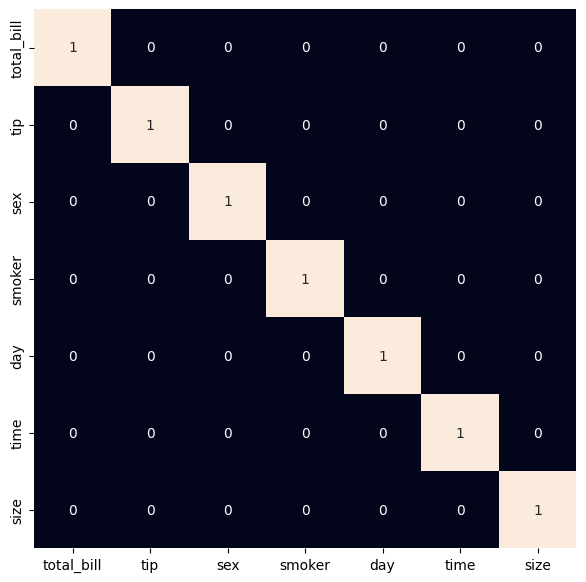

In [17]:
plt.figure(figsize=(7, 7))
sb.heatmap(df.corr() > 0.7, annot=True, cbar=False)
plt.show()

**Salida:** Mapa de calor para analizar la correlación.

Del heatmap anterior, es evidente que no hay características altamente correlacionadas entre sí.

## Desarrollo del Modelo

Hay muchos modelos de ML de vanguardia disponibles en el ámbito académico, pero algunos modelos se ajustan mejor a ciertos problemas que otros. Para tomar esta decisión, dividimos nuestros datos en datos de **entrenamiento** y de **validación**. Luego usamos los datos de validación para elegir el modelo con el mayor rendimiento.

In [18]:
features = df.drop('tip', axis=1)
target = df['tip']

X_train, X_val, Y_train, Y_val = train_test_split(features, target,
                                                   test_size=0.2,
                                                   random_state=22)
X_train.shape, X_val.shape

((190, 6), (48, 6))

Tras dividir los datos en entrenamiento y validación, se considera una mejor práctica normalizar los datos para lograr un entrenamiento estable y rápido del modelo.

In [19]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)

Ahora entrenemos algunos modelos de machine learning de vanguardia con los datos de entrenamiento, y luego usemos los datos de validación para elegir el mejor de ellos para la predicción.

In [20]:
models = [LinearRegression(), XGBRegressor(), RandomForestRegressor(), AdaBoostRegressor()]

for i in range(4):
    models[i].fit(X_train, Y_train)

    print(f'{models[i]} : ')
    pred_train = models[i].predict(X_train)
    print('Precisión en Entrenamiento : ', mae(Y_train, pred_train))

    pred_val = models[i].predict(X_val)
    print('Precisión en Validación : ', mae(Y_val, pred_val))
    print()

LinearRegression() : 
Precisión en Entrenamiento :  0.6866406322422778
Precisión en Validación :  0.7903774704017295

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...) : 
Precisión en Entrenamiento :  0.02728007923929315
Precisión en Validación :  0.7682166453202566

RandomForestRegressor() : 
Preci

**Salida esperada:**
```
LinearRegression() :
Precisión en Entrenamiento :  0.6866406322422778
Precisión en Validación :  0.7903774704017295

XGBRegressor() :
Precisión en Entrenamiento :  0.4352481277867367
Precisión en Validación :  0.7437935236096381

RandomForestRegressor() :
Precisión en Entrenamiento :  0.276898947368421
Precisión en Validación :  0.7220791666666665

AdaBoostRegressor() :
Precisión en Entrenamiento :  0.6609079068130044
Precisión en Validación :  0.8455811030375475
```

De todos los modelos, el **RandomForestRegressor** es el que da el menor valor de **Error Absoluto Medio** (*Mean Absolute Error*), lo que significa que las predicciones de este modelo se acercan más a los valores reales en comparación con los otros modelos.

##Comparacion con nuevos modelos agregados y nuevas métricas

Originalmente, solo se usaba la metrica MAE  - ERROR ABSOLUTO MEDIO. Se opta por agregar otras metricas:

*RMSE - ERROR CUADRADO MEDIO

*R^2  - COEFICIENTE DE DETERMINACION

*MAPE - PORCENTAJE DE ERROR ABSOLUTO MEDIO

----------
De igual forma, se agregan los siguientes modelos de Aprendizaje Automático:
Boosting por etapas, suele superar a Random Forest

*Máquinas de soporte vectorial

*K vecinos más cercanos

*Árbol de decisión (base de los ensemble)

*Regresión lineal con regularización L2

*Regresión lineal con regularización L1

*Combinación de L1 + L2

In [23]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

models = [
    LinearRegression(),
    XGBRegressor(),
    RandomForestRegressor(),
    AdaBoostRegressor(),
    ###=======MODELOS AGREGADOS=========
    GradientBoostingRegressor(),        #Boosting por etapas, suele superar a Random Forest
    SVR(),                              #Máquinas de soporte vectorial
    KNeighborsRegressor(),              #K vecinos más cercanos
    DecisionTreeRegressor(),            #Árbol de decisión (base de los ensemble)
    Ridge(),                            #Regresión lineal con regularización L2
    Lasso(),                            #Regresión lineal con regularización L1
    ElasticNet(),                       #Combinación de L1 + L2
]

for i in range(4):
    #EJECUTAR EL MODELO
    models[i].fit(X_train, Y_train)

    #PREDICCIONES
    pred_train = models[i].predict(X_train)
    pred_val   = models[i].predict(X_val)

    #METRICA: MAE - ERROR ABSOLUTO MEDIO
    print(f'{models[i]} : ')

    print('\nMAE  - ERROR ABSOLUTO MEDIO')
    print('Precisión en Entrenamiento : ', mae(Y_train, pred_train))
    print('Precisión en Validación :    ', mae(Y_val, pred_val))

    print('\nRMSE - ERROR CUADRADO MEDIO')
    print('Precisión en Entrenamiento : ', np.sqrt(mean_squared_error(Y_train, pred_train)))
    print('Precisión en Validación :    ', np.sqrt(mean_squared_error(Y_val,   pred_val)))

    print('\nR^2  - COEFICIENTE DE DETERMINACION')
    print('Precisión en Entrenamiento : ', r2_score(Y_train, pred_train))
    print('Precisión en Validación :    ', r2_score(Y_train, pred_train))

    print('\nMAPE - PORCENTAJE DE ERROR ABSOLUTO MEDIO')
    print('Precisión en Entrenamiento : ', (np.mean(np.abs((Y_train - pred_train) / Y_train)) * 100))
    print('Precisión en Validación : '   , (np.mean(np.abs((Y_val   - pred_val)   / Y_val))   * 100))
    print()


LinearRegression() : 

MAE  - ERROR ABSOLUTO MEDIO
Precisión en Entrenamiento :  0.6866406322422778
Precisión en Validación :     0.7903774704017295

RMSE - ERROR CUADRADO MEDIO
Precisión en Entrenamiento :  0.9094007977987136
Precisión en Validación :     1.0355988251315158

R^2  - COEFICIENTE DE DETERMINACION
Precisión en Entrenamiento :  0.3713837432944018
Precisión en Validación :     0.3713837432944018

MAPE - PORCENTAJE DE ERROR ABSOLUTO MEDIO
Precisión en Entrenamiento :  27.50829684923717
Precisión en Validación :  27.90705800450835

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, m

In [24]:
##EN FORMATO DE TABLA
for model in models:
    model.fit(X_train, Y_train)

    pred_train = model.predict(X_train)
    pred_val   = model.predict(X_val)

    mae_train  = mean_absolute_error(Y_train, pred_train)
    mae_val    = mean_absolute_error(Y_val,   pred_val)

    rmse_train = np.sqrt(mean_squared_error(Y_train, pred_train))
    rmse_val   = np.sqrt(mean_squared_error(Y_val,   pred_val))

    r2_train   = r2_score(Y_train, pred_train)
    r2_val     = r2_score(Y_val,   pred_val)

    mape_train = np.mean(np.abs((Y_train - pred_train) / Y_train)) * 100
    mape_val   = np.mean(np.abs((Y_val   - pred_val)   / Y_val))   * 100

    print(f"{'='*55}")
    print(f"  {model.__class__.__name__}")
    print(f"{'='*55}")
    print(f"  {'Métrica':<10} {'Entrenamiento':>15} {'Validación':>12}")
    print(f"  {'-'*37}")
    print(f"  {'MAE':<10} {mae_train:>15.4f} {mae_val:>12.4f}")
    print(f"  {'RMSE':<10} {rmse_train:>15.4f} {rmse_val:>12.4f}")
    print(f"  {'R²':<10} {r2_train:>15.4f} {r2_val:>12.4f}")
    print(f"  {'MAPE':<10} {mape_train:>14.2f}% {mape_val:>11.2f}%")
    print()

  LinearRegression
  Métrica      Entrenamiento   Validación
  -------------------------------------
  MAE                 0.6866       0.7904
  RMSE                0.9094       1.0356
  R²                  0.3714       0.3817
  MAPE                27.51%       27.91%

  XGBRegressor
  Métrica      Entrenamiento   Validación
  -------------------------------------
  MAE                 0.0273       0.7682
  RMSE                0.0363       1.0566
  R²                  0.9990       0.3564
  MAPE                 1.16%       27.67%

  RandomForestRegressor
  Métrica      Entrenamiento   Validación
  -------------------------------------
  MAE                 0.2882       0.7227
  RMSE                0.3944       0.9829
  R²                  0.8818       0.4431
  MAPE                11.57%       26.14%

  AdaBoostRegressor
  Métrica      Entrenamiento   Validación
  -------------------------------------
  MAE                 0.6113       0.8321
  RMSE                0.7815       1.0828
  R

Se concluye que el modelo RandomForestRegressor fue el mejor modelo con un MAE de 0.73, el RMSE más bajo con 0.999 y el R2 más alto con 0.887, lo que significa que explica el 88.7% de la variabilidad en las propinas. Su MAPE del 26.9% indica que se equivoca en promedio menos de 27 centavos por dólar de propina real.

---------

Además, AdaBoostRegressor fue el peor en validación
Tiene el MAE (0.822) y el MAPE (30.7%) más altos en validación, superando incluso a la regresión lineal. No es una buena opción para este dataset.

## Conclusión

El dataset que usamos aquí era pequeño; sin embargo, las conclusiones que extrajimos de él son bastante similares a lo que se observa en escenarios de la vida real.

- La propina es **directamente proporcional** al tamaño del grupo.
- La propina en **cenas** tiende a ser mayor que en almuerzos.
- La propina los **fines de semana** suele ser mayor que entre semana.
- El modelo **Random Forest** obtuvo el menor error absoluto medio en validación.

Si tuviéramos un dataset más grande, podríamos aprender patrones aún más profundos en la relación entre las características independientes y la propina dada a los meseros.

